# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [7]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

ETSU_NAVY = "#00053E"
ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


## Step 1: Load the data

Change the path to the real Wholesale file when you have it.

In [8]:
# GIVEN: load the data
df = pd.read_csv("wholesale_sample.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1,1,4181,10024,26577,1979,9194,1151
1,2,3,3346,4848,14310,1155,2666,1768
2,2,3,3687,8096,10837,870,7701,1345
3,1,2,3008,6327,16926,1032,5303,1582
4,2,3,4704,13163,20537,1507,3073,1267


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [9]:
# TODO: explore the data
print(df.shape)
print()
print(df.info())
print()
print(df[spend_cols].describe())




(150, 8)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           150 non-null    int64
 1   Region            150 non-null    int64
 2   Fresh             150 non-null    int64
 3   Milk              150 non-null    int64
 4   Grocery           150 non-null    int64
 5   Frozen            150 non-null    int64
 6   Detergents_Paper  150 non-null    int64
 7   Delicassen        150 non-null    int64
dtypes: int64(8)
memory usage: 9.5 KB
None

              Fresh          Milk       Grocery       Frozen  \
count    150.000000    150.000000    150.000000   150.000000   
mean   10298.826667   5422.726667   7938.353333  3017.386667   
std     8398.147983   3820.906314   7053.621991  1977.922844   
min     2043.000000   1313.000000   1451.000000   760.000000   
25%     3923.250000   2524.250000   2877.750000  1461.500000   
50%     5748.500000

## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [10]:
# TODO: build X from the spend columns and scale it
X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)




## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

Text(0, 0.5, 'avg silhouette')

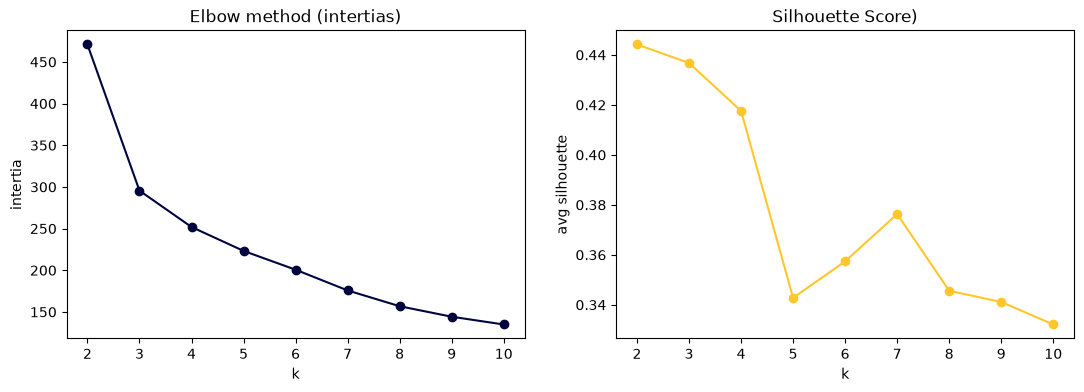

In [11]:
# TODO: loop over k, collect inertia and silhouette, then plot both
# Hint:
# ks = range(2, 11)
# inertias, sils = [], []
# for k in ks:
#     km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
#     inertias.append(km.inertia_)
#     sils.append(silhouette_score(Xs, km.labels_))
# then make two plots: ks vs inertias, and ks vs sils


ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize =(13, 4))
ax[0].plot(list(ks), inertias, "o-", color=ETSU_NAVY)
ax[0].set_title("Elbow method (intertias)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("intertia")

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("Silhouette Score)"); ax[1].set_xlabel("k"); ax[1].set_ylabel("avg silhouette")


**Your chosen k and why:**

*(write 1 to 2 sentences here)*

## Step 5: Fit k-means with your chosen k

In [24]:
# TODO: fit KMeans at your chosen k and attach the labels to df
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_



## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

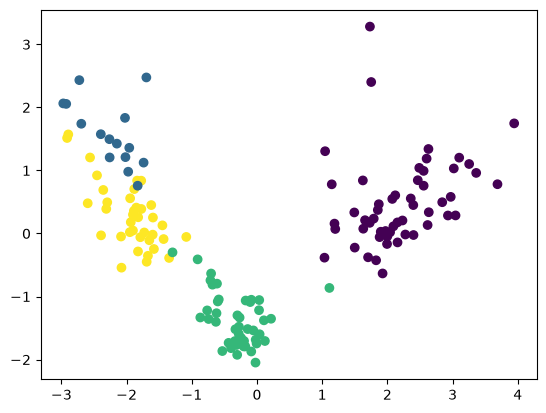

In [25]:
# TODO: project Xs to 2D with PCA and scatter it, colored by df["cluster"]
pcs = PCA(n_components=2).fit_transform(Xs)
plt.scatter(pcs[:,0], pcs[:,1], c=df["cluster"])






## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

In [26]:
# TODO: build a profile table of per-cluster averages
print(df.groupby("cluster")[spend_cols].mean().round(0))
print(df["cluster"].value_counts())




           Fresh    Milk  Grocery  Frozen  Detergents_Paper  Delicassen
cluster                                                                
0         4160.0  9696.0  15961.0  1548.0            6345.0      1668.0
1        20884.0  3051.0   3646.0  4885.0             840.0      3793.0
2         5578.0  2837.0   3075.0  2144.0            1415.0      1232.0
3        20581.0  3223.0   3753.0  5444.0             806.0      1897.0
cluster
0    54
2    44
3    37
1    15
Name: count, dtype: int64


## Step 8: Findings

1. **How many clusters did you choose, and why?** (what the elbow and silhouette showed)
I chose four clusters because after looking at the silhouette model it dropped down after four and began to flatten out.

2. **Describe each segment** in plain language. What kind of customer is it (for example, a grocery-heavy retailer vs a fresh-and-frozen restaurant supplier)?
cluster zero is high grocery and milk with medium everything else. cluster one is heavy fresh low everything else. cluster two is low in each category. cluster three is very similar to cluster one but differs slightly in frozen and delicassen
3. **One action per segment:** what should the distributor do differently for each group?
invest more in the fresh, grocery, and milk categories since they had the highest spenders.
4. **One limitation:** what would you want to check or try next (different k, more features, outliers)?
I did look at more k but only 5 instead of 4. I would like to see how it differs with a larger amount to see how precise they get.
## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing